# Freddie Mac Loan Default Prediction (2016 Originations)

**Goal:** Predict whether a mortgage will become delinquent (90+ days late) within its first 3 years, using only information known on the day the loan was made.

**Data:** [Freddie Mac Single-Family Loan-Level Dataset](https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset), 2016 sample file
- **Origination data**: one row per loan (50,000 loans), with borrower and loan details at the time the loan was made (credit score | loan-to-value | debt-to-income | etc.)
- **Performance data**: one row per loan *per month* (~3.4 million rows), showing whether the borrower was current or behind on payments each month

**Approach:** Build a default flag (`ever_90dpd`) from the monthly performance data, join it to the origination features, clean the data, and compare **two models**:
1. **Model 1: Logistic Regression** (simple, interpretable baseline) → `sklearn.linear_model`
2. **Model 2: Gradient Boosting** (`HistGradientBoostingClassifier`, a tree-based model that can pick up non-linear patterns) → `sklearn.ensemble`

I built this project to learn more about the domain of mortgage / credit risk domain, so some of the markdown and comments are my own notes on how the data and the business work.

### Notebook Outline
| Step | What happens |
|---|---|
| 0 | Imports |
| 1 | Load the origination data |
| 2 | Load the performance data and look at the status codes |
| 3 | Build the target: `ever_90dpd` |
| 4 | Join the target to the origination features |
| 5 | Clean the features (filler codes, HARP loans, useless columns, CLTV) |
| 6 | EDA: default rate by FICO, LTV, and DTI |
| 7 | Prep the text columns and one-hot encode |
| 8 | Train/test split |
| 9 | **Model 1:** Logistic Regression (cross-validation) |
| 10 | **Model 2:** Gradient Boosting (cross-validation) and comparison |
| 11 | Final model: fit on the full training set, score on the test set |
| 12 | What drives default risk? (coefficients) |
| 13 | Takeaways and next steps |

## Step 0: Imports
Everything used in the notebook is imported here.

In [49]:
# Data handling
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Modeling
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Versions used
print(pd.__version__, sklearn.__version__)

3.1.0 1.9.1


## Step 1: Load the Origination Data
The Freddie Mac files are pipe-delimited (`|`) and have **no header row**. The column names come in a separate header file, so they're passed in as the column labels when loading the data (`names=`).

Each row in this file is one loan, as it looked on the day it was made.

In [50]:
# Read the header file and turn it into a list of column names
with open("data/origination_data_file_header.txt") as f:
    original_cols = f.read().strip().split("|")  # split on the pipes to get the list

# Load the origination data (one row per loan)
orig = pd.read_csv(
    "data/sample_orig_2016.txt",
    sep="|",                 # pipe-delimited, not commas
    header=None,             # no header row in the file
    names=original_cols,     # use the names from the header file
    low_memory=False)        # read the whole file before guessing dtypes (stops the mixed-type warning)

# Should be 50,000 loans x 31 columns
print(orig.shape)
orig.head()

(50000, 31)


,CLASSIC FICO,FIRST PAYMENT DATE,FIRST TIME HOMEBUYER INDICATOR,MATURITY DATE,METROPOLITAN STATISTICAL AREA (MSA) OR METROPOLITAN DIVISION,MORTGAGE INSURANCE PERCENTAGE (MI %),NUMBER OF UNITS,OCCUPANCY STATUS,ORIGINAL COMBINED LOAN-TO-VALUE (CLTV),ORIGINAL DEBT-TO-INCOME (DTI) RATIO,...,ORIGINAL LOAN TERM,NUMBER OF BORROWERS,SELLER NAME,SUPER CONFORMING FLAG,PRE-HARP LOAN SEQUENCE NUMBER,SPECIAL ELIGIBILITY PROGRAM,HARP INDICATOR,PROPERTY VALUATION METHOD,INTEREST ONLY (I/O) INDICATOR,VANTAGESCORE 4.0
0,686,201604,N,203603,39820.0,0,1,P,65,41,...,240,2,OTHER,N,NaN,NaN,N,7,N,9999
1,774,201603,Y,204602,29620.0,30,1,P,95,30,...,360,1,OTHER,N,NaN,NaN,N,7,N,9999
2,808,201604,N,203103,30700.0,0,1,P,81,15,...,180,2,OTHER,N,NaN,NaN,N,7,N,9999
3,784,201603,N,204602,NaN,0,1,P,82,42,...,360,2,OTHER,N,NaN,NaN,N,7,N,9999
4,798,201603,N,204602,47664.0,0,1,P,28,22,...,360,1,OTHER,N,NaN,NaN,N,7,N,9999


In [51]:
orig.columns.to_list()

['CLASSIC FICO',
 'FIRST PAYMENT DATE',
 'FIRST TIME HOMEBUYER INDICATOR',
 'MATURITY DATE',
 'METROPOLITAN STATISTICAL AREA (MSA) OR METROPOLITAN DIVISION',
 'MORTGAGE INSURANCE PERCENTAGE (MI %)',
 'NUMBER OF UNITS',
 'OCCUPANCY STATUS',
 'ORIGINAL COMBINED LOAN-TO-VALUE (CLTV)',
 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO',
 'ORIGINAL UPB',
 'ORIGINAL LOAN-TO-VALUE (LTV)',
 'ORIGINAL INTEREST RATE',
 'CHANNEL',
 'PREPAYMENT PENALTY INDICATOR',
 'AMORTIZATION TYPE',
 'PROPERTY STATE',
 'PROPERTY TYPE',
 'POSTAL CODE',
 'LOAN IDENTIFIER',
 'LOAN PURPOSE',
 'ORIGINAL LOAN TERM',
 'NUMBER OF BORROWERS',
 'SELLER NAME',
 'SUPER CONFORMING FLAG',
 'PRE-HARP LOAN SEQUENCE NUMBER',
 'SPECIAL ELIGIBILITY PROGRAM',
 'HARP INDICATOR',
 'PROPERTY VALUATION METHOD',
 'INTEREST ONLY (I/O) INDICATOR',
 'VANTAGESCORE 4.0']

## Step 2: Load the Performance Data
The performance file has a row for every loan, every month(~3.4 million rows).
I decided on 5 columns to build the target - `usecols` loads just those.

| Column | What it is |
|---|---|
| `LOAN IDENTIFIER` | Key to join back on the origination data |
| `PERIOD` | # month this row's loan status was reported (YYYYMM) |
| `LOAN AGE` | Months since the loan started |
| `CURRENT LOAN DELINQUENCY STATUS` | How many months behind is the borrower |
| `ZERO BALANCE CODE` | Why the loan ended, if it ended that month |

In [52]:
# Read the performance header file into a list of column names
with open("data/performance_data_file_header.txt") as f2:
    perf_cols = f2.read().strip().split("|")

# Only the columns I need to build the target
keep_cols = [
    "LOAN IDENTIFIER",                  # join key back to orig
    "PERIOD",                           # reporting month
    "LOAN AGE",                         # months since origination (used for the 36-month window)
    "CURRENT LOAN DELINQUENCY STATUS",  # 0, 1, 2, 3+ months late, or RA
    "ZERO BALANCE CODE"                 # why the loan ended (payoff, short sale, REO, etc.)
]

# Load the performance data (one row per loan per month)
perf = pd.read_csv(
    "data/sample_perf_2016.txt",
    sep="|",
    header=None,
    names=perf_cols,      # pass all the names so pandas knows which column is which
    usecols=keep_cols,    # but only load the 5 I need
    low_memory=False)

# Should be 5 columns and millions of rows
print(perf.shape)
perf.head()

(3421458, 5)


,LOAN IDENTIFIER,PERIOD,CURRENT LOAN DELINQUENCY STATUS,LOAN AGE,ZERO BALANCE CODE
0,F16Q10000006,201603,00,0,NaN
1,F16Q10000006,201604,00,1,NaN
2,F16Q10000006,201605,00,2,NaN
3,F16Q10000006,201606,00,3,NaN
4,F16Q10000006,201607,00,4,NaN


In [53]:
# Which Zero Balance Codes actually show up in this sample?
display(sorted(perf['ZERO BALANCE CODE'].dropna().unique().tolist()))

# How many loans ended with each Zero Balance Code
# NaN (still active) gets skipped, and a loan only gets a code in its last month,
# so these counts are roughly the number of loans per exit type
# .sort_index() puts them in code order (1, 2, 3, 9...) instead of by count
display(perf['ZERO BALANCE CODE'].value_counts().sort_index())

[1.0, 2.0, 3.0, 9.0, 15.0, 16.0, 96.0]

ZERO BALANCE CODE
1.0     36027
2.0        41
3.0         7
9.0        30
15.0       17
16.0       72
96.0       63
Name: count, dtype: int64

### Zero Balance Codes

The **Zero Balance Code** shows *why* a loan's balance went to zero (i.e., why the loan left the dataset).
`NaN` means the loan was still active that month, which is true for most rows.

| Code | Meaning | Counts as Default? |
|---|---|---|
| `NaN` | Loan still active that month | No |
| `1` | **Prepaid or matured**: borrower paid it off, sold the house, or refinanced | No (most common exit) |
| `2` | **Third-party sale**: house sold to an outside buyer at the foreclosure auction | **Yes** |
| `3` | **Short sale or charge-off**: house sold for less than what was owed, or the debt was written off | **Yes** |
| `9` | **REO disposition**: the lender took the house through foreclosure (`RA`) and has now sold it | **Yes** |
| `15` | **Note sale**: Freddie Mac sold the loan itself to an investor, usually because it was in trouble | Usually (almost always went 90+ first) |
| `16` | **Reperforming loan sale**: loan went bad, recovered, then was sold off | Usually (would already have been 90+ at some point) |
| `96` | **Repurchase**: the original lender had to buy the loan back, usually over a paperwork or underwriting defect | No (a defect, not a borrower failing to pay) |

**Notes:**
- The codes show as decimals (`1.0`, `96.0`) because `NaN` counts as a float, which turns the whole column into floats.
- **For the target:** codes **2, 3, and 9** are a backup catch.
If a loan ended in foreclosure without its monthly data ever showing 3+ months delinquent,
these codes still flag it as a default.

In [54]:
# What values does the delinquency status take?
display(perf['CURRENT LOAN DELINQUENCY STATUS'].unique())

# How many monthly rows are in each status
# (these are loan-months, not loans, since every loan shows up once a month)
display(perf['CURRENT LOAN DELINQUENCY STATUS'].value_counts())

<ArrowStringArray>
['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12',
 '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25',
 '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38',
 '39', '40', 'RA', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50',
 '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63',
 '64', '65', '66', '67', '68', '69', '70']
Length: 72, dtype: str

CURRENT LOAN DELINQUENCY STATUS
00    3367132
01      24583
02       7110
03       3912
04       2806
       ...   
63          3
67          1
68          1
69          1
70          1
Name: count, Length: 72, dtype: int64

### Delinquency Status
`CURRENT LOAN DELINQUENCY STATUS` is the number of **months** the borrower is behind:

| Value | Meaning |
|---|---|
| `00` | Current (paid on time) |
| `01` | 30-59 days late |
| `02` | 60-89 days late |
| `03` and up | 90+ days late (**serious delinquency**, the industry's usual "default" line) |
| `RA` | REO Acquisition: the lender took the house through foreclosure |

It's stored as text because of the `RA` value, so it needs converting before performing calcualations on it (Step 3).

## Step 3: Build the Target (`ever_90dpd`)

**Definition:** a loan is flagged as a default (`ever_90dpd = 1`) if **within its first 36 months**:
1. it was ever **90+ days delinquent** (delinquency status of 3 or more, or `RA`), **or**
2. it ended with a **default-type Zero Balance Code** (2, 3, or 9) as a backup check

**Approach:**
1. Convert delinquency status to a number (`months_dlq`)
2. Keep only the first 36 months of data for each loan
3. Collapse to one row per loan (the worst delinquency it ever hit)
4. Add 'Zero Balance Code' backup check and build the 0/1 flag

### 3a. Convert delinquency status to a number
`RA` gets mapped to `99`, so it counts as "3 or more" (bad) but is still easy to tell apart from real values (the highest real value is 70).

In [55]:
# Numeric copy of the delinquency status (original column stays as is)
# 'RA' (foreclosure completed) → 99 so it counts as 3+ (bad)
# but stays separate from real values (real max is 70)
perf['months_dlq'] = (
    perf['CURRENT LOAN DELINQUENCY STATUS']
    .replace('RA', '99')   # still text here, so '99' needs quotes
    .astype(int)           # then convert the column to integers
)
perf['months_dlq'].max()

np.int64(99)

### 3b. Limit to the first 36 months
Checking `LOAN AGE` first to make sure it's already numeric before filtering on it.

In [56]:
print(perf['LOAN AGE'].unique())
print(perf['LOAN AGE'].dtype)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125]
int64


In [57]:
# Keep only the first 36 months (3 years) of each loan
perf_36 = perf[perf['LOAN AGE'] <= 36].copy()
perf_36.shape

(1685635, 6)

### 3c. Collapse to one row per loan
`groupby` + `max` gives each loan's **worst** delinquency inside the window. If that's 3 months or higher, the loan was 90+ days late at some point.

In [58]:
# One row per loan: the worst (highest) delinquency status inside the 36-month window
# max_months_dlq >= 3 means the loan was 90+ days late at some point → this becomes the "bad" flag
loan_max = (
    perf_36.groupby('LOAN IDENTIFIER')
    .agg(
        max_months_dlq=('months_dlq', 'max')   # new column name = (column to use, function to apply)
    ).reset_index()          # turn LOAN IDENTIFIER back into a normal column
)
# Should be ~50,000 rows (one per loan), 2 columns
print(loan_max.shape)
loan_max.head()

(49871, 2)


,LOAN IDENTIFIER,max_months_dlq
0,F16Q10000006,0
1,F16Q10000027,0
2,F16Q10000048,0
3,F16Q10000054,0
4,F16Q10000076,0


### 3d. Where did 129 loans go?
`loan_max` has **49,871** loans, but the origination file has **50,000**. Two possible reasons:
1. The 129 loans were never in the performance file at all, **or**
2. They are in the performance file, but have no rows inside the 36-month window, so the filter in 3b dropped them

If the full performance file has 50,000 unique loans, it's reason 2.

In [59]:
# How many unique loans are in the full performance file?
# 50,000 → the window dropped them (reason 2) | 49,871 → they were never in perf (reason 1)
perf['LOAN IDENTIFIER'].nunique()

50000

All 50,000 loans are in the performance file, so the 129 were dropped by the **36-month window filter** (Step 3b). The check below finds those loans and shows the youngest `LOAN AGE` each one ever reports. If they never show a loan age of 36 or less, that explains why the filter removed them.

In [60]:
# Loan IDs in the full perf file that didn't make it into loan_max
#   set() = a collection of unique values, and subtracting two sets
#   leaves whatever is in the first one but not the second
dropped_ids = set(perf['LOAN IDENTIFIER']) - set(loan_max['LOAN IDENTIFIER'])
print(f"Loans dropped by the window: {len(dropped_ids)}")

# Youngest loan age each of those loans ever reports
perf[perf['LOAN IDENTIFIER'].isin(dropped_ids)].groupby('LOAN IDENTIFIER')['LOAN AGE'].min().describe()

Loans dropped by the window: 129


count    129.000000
mean      38.589147
std        1.549256
min       37.000000
25%       37.000000
50%       38.000000
75%       39.000000
max       44.000000
Name: LOAN AGE, dtype: float64

### 3e. How far behind did loans get?
Distribution of each loan's worst delinquency in the window. Most loans (~93%) never missed a payment. Everything at **3 and above** will be flagged as a default.

In [61]:
print(loan_max['max_months_dlq'].value_counts().sort_index())

# As percentages
(loan_max['max_months_dlq'].value_counts(normalize=True).sort_index()*100).round(2)

max_months_dlq
0     46427
1      2537
2       356
3       145
4        85
5        98
6        49
7        26
8        29
9        23
10        7
11       10
12       11
13        8
14        4
15        7
16        5
17        8
18        1
19        2
20        4
21        2
22        5
25        1
26        2
29        2
30        1
33        1
34        1
36        1
99       13
Name: count, dtype: int64


max_months_dlq
0     93.09
1      5.09
2      0.71
3      0.29
4      0.17
5      0.20
6      0.10
7      0.05
8      0.06
9      0.05
10     0.01
11     0.02
12     0.02
13     0.02
14     0.01
15     0.01
16     0.01
17     0.02
18     0.00
19     0.00
20     0.01
21     0.00
22     0.01
25     0.00
26     0.00
29     0.00
30     0.00
33     0.00
34     0.00
36     0.00
99     0.03
Name: proportion, dtype: float64

### 3f. Zero Balance Code backup check
Some loans could end in foreclosure or a short sale without the monthly data ever showing 3+ months late. Codes **2, 3, and 9** catch those.

**Note to self:** a loan only gets a Zero Balance Code on its **last** monthly record. After that month it stops showing up in the perfromace data file.

In [62]:
# ZERO BALANCE CODE = how the loan ended:
#   2, 3, 9 = defaults (third-party sale, short sale/charge-off, REO sale)
#   NaN = still active, 1 = paid off, 96 = repurchase (not borrower defaults)
#   15, 16 = sold after going bad (already caught by max_months_dlq >= 3)
# months_dlq = how far behind the borrower is each month
#   (built from 'CURRENT LOAN DELINQUENCY STATUS' in 3a)

# Keep only rows where the loan ended in a default-type exit
# (the code is only on a loan's final record, so this is one row per loan)
defaulted = perf_36[perf_36['ZERO BALANCE CODE'].isin([2, 3, 9])].copy()

# Unique loan IDs that ended in default
zbc_default_ids = defaulted['LOAN IDENTIFIER'].unique().tolist()

# Loans that hit 90+ days late at some point in the window
dlq_90 = loan_max[loan_max['max_months_dlq'] >= 3]

# Of the ZBC default loans, how many also hit 90+ days late?
overlap = dlq_90['LOAN IDENTIFIER'].isin(zbc_default_ids).sum()

print(f"Loans that ended in a default exit (ZBC 2, 3, 9): {len(zbc_default_ids):,}")
print(f"Loans that hit 90+ days late (max_months_dlq >= 3): {len(dlq_90):,}")
print(f"ZBC default loans that were also 90+ days late:   {overlap:,} of {len(zbc_default_ids):,}")

Loans that ended in a default exit (ZBC 2, 3, 9): 26
Loans that hit 90+ days late (max_months_dlq >= 3): 551
ZBC default loans that were also 90+ days late:   26 of 26


### Why most 90+ day loans don't have a default Zero Balance Code (ZBC)
**551** loans hit 90+ days late, but only **26** ended with a default-type ZBC (2, 3, or 9). That leaves **525** that went seriously delinquent without a ZBC.

That's because a ZBC only shows up when a loan actually **ends**. Hitting 90+ days late doesn't end a loan. After a borrower gets that far behind, a few things can happen:
- **They catch up (cure):** the borrower pays what they owe and goes back to current
- **Loan modification:** the lender changes the terms (lower payment, longer term) so the borrower can keep paying
- **Still delinquent when the window ends:** foreclosure often takes more than a year, so many loans never finish the process inside 36 months
- **Sold off (ZBC 15 or 16):** Freddie Mac sells the troubled loan to an investor, which is a different exit code than 2, 3, or 9
- **Paid off (ZBC 1):** some borrowers sell the house or refinance after falling behind

### 3g. Build the 0/1 target
`ever_90dpd = 1` if **either** check is true. The printout also shows how many extra defaults the Zero Balance backup adds on top of the delinquency check.

In [63]:
# Target column ['ever_90dpd']: 1 if either check is True, 0 if neither
# Check 1: loan ended in a default-type exit (Zero Balance Code 2, 3, 9)
# Check 2: loan was ever 90+ days late (max_months_dlq >= 3)
loan_max['ever_90dpd'] = (
    (loan_max['LOAN IDENTIFIER'].isin(zbc_default_ids)) |
    (loan_max['max_months_dlq'] >= 3)
).astype(int)   # True/False → 1/0

# Loans with max_months_dlq of 3 or more (delinquency check only)
# (True = 1 and False = 0, so .sum() counts the Trues)
months_dlq_defaults = (loan_max['max_months_dlq'] >= 3).sum()

# Total defaults using both checks
total_defaults = loan_max['ever_90dpd'].sum()

# Default rate = defaults / total loans
default_rate = loan_max['ever_90dpd'].mean() * 100   # mean of a 0/1 column = share of 1s

print(f"Loans 90+ days late (max_months_dlq >= 3): {months_dlq_defaults:,}")
print(f"Total defaults (both checks):       {total_defaults:,}")
print(f"Added by Zero Balance backup:       {total_defaults - months_dlq_defaults:,}")
print(f"Default rate:                       {default_rate:.2f}% of {len(loan_max):,} loans")

Loans 90+ days late (max_months_dlq >= 3): 551
Total defaults (both checks):       551
Added by Zero Balance backup:       0
Default rate:                       1.10% of 49,871 loans


The Zero Balance backup added **0** loans. Every loan that ended in a default-type exit had already hit 90+ days late in the monthly data first. It's still worth keeping in the code as a safety net if this gets run on other years.

**Default rate is ~1.1%.** That's a heavily **imbalanced** target (about 1 default for every 90 good loans), which affects how the models are set up and scored later.

## Step 4: Join the Target to the Origination Features
Now each loan's origination details (the features) get matched with its `ever_90dpd` flag (the target).

`how='inner'` keeps only loans that are in both tables, so the 129 loans dropped by the 36-month window (Step 3d) don't make it into `model_df`.

In [64]:
# Attach the target (ever_90dpd) to each loan's origination features
model_df = orig.merge(
    loan_max[['LOAN IDENTIFIER', 'ever_90dpd']],  # double brackets → DataFrame with just the ID + target
    on='LOAN IDENTIFIER',                         # join key, same name in both tables
    how='inner'   # only loans in both tables (drops the 129 from the 36-month window)
)

# Should be (49871, 32), and the default rate should match the print above
print(model_df.shape)
print(f"Default rate: {model_df['ever_90dpd'].mean() * 100:.2f}%")

(49871, 32)
Default rate: 1.10%


## Step 5: Clean the Features
Freddie Mac uses **filler codes** for missing values instead of leaving them blank. For example `999` for a missing DTI or `9999` for a missing credit score. If those are left in, the model would treat a DTI of 999 as a real number.

`.describe()` to find strage values.

In [65]:
model_df.describe()

,CLASSIC FICO,FIRST PAYMENT DATE,MATURITY DATE,METROPOLITAN STATISTICAL AREA (MSA) OR METROPOLITAN DIVISION,MORTGAGE INSURANCE PERCENTAGE (MI %),NUMBER OF UNITS,ORIGINAL COMBINED LOAN-TO-VALUE (CLTV),ORIGINAL DEBT-TO-INCOME (DTI) RATIO,ORIGINAL UPB,ORIGINAL LOAN-TO-VALUE (LTV),ORIGINAL INTEREST RATE,POSTAL CODE,ORIGINAL LOAN TERM,NUMBER OF BORROWERS,PROPERTY VALUATION METHOD,VANTAGESCORE 4.0,ever_90dpd
count,49871.000000,49871.000000,49871.000000,44820.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.000000,49871.0,49871.0,49871.000000
mean,748.739889,201623.326623,204255.876682,30260.429585,6.183333,1.029937,73.836278,83.007800,233698.642498,73.208017,3.790716,568.071304,316.895490,1.494195,7.0,9999.0,0.011049
std,46.725493,35.296806,623.761476,11293.363342,11.269286,0.232091,17.385053,211.865657,118685.900974,17.366299,0.472945,300.566782,74.842601,0.499971,0.0,0.0,0.104531
min,456.000000,201602.000000,202405.000000,10180.000000,0.000000,1.000000,5.000000,1.000000,10000.000000,3.000000,2.250000,7.000000,96.000000,1.000000,7.0,9999.0,0.000000
25%,716.000000,201606.000000,203701.000000,19340.000000,0.000000,1.000000,65.000000,28.000000,141000.000000,64.000000,3.500000,306.000000,240.000000,1.000000,7.0,9999.0,0.000000
50%,757.000000,201609.000000,204606.000000,31540.000000,0.000000,1.000000,78.000000,36.000000,214000.000000,78.000000,3.750000,582.000000,360.000000,1.000000,7.0,9999.0,0.000000
75%,787.000000,201612.000000,204609.000000,40060.000000,0.000000,1.000000,85.000000,43.000000,311000.000000,84.000000,4.125000,852.000000,360.000000,2.000000,7.0,9999.0,0.000000
max,832.000000,202010.000000,204807.000000,49740.000000,40.000000,4.000000,336.000000,999.000000,975000.000000,336.000000,6.000000,999.000000,360.000000,2.000000,7.0,9999.0,1.000000


### 5a. DTI filler code (999)
**DTI (Debt-to-Income)** = the borrower's monthly debt payments ÷ their monthly income. A DTI of 40 means 40% of income goes to debt (car payments, loans, credit cards, etc.). Freddie Mac's max is 50, so the max of **999** above is the filler code for **"not available."**

View the `NaN` first to do see what to do with them.

In [66]:
# How many loans have the DTI filler code, and what share of the data is that?
dti_999 = (model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'] == 999).sum()
print(f"Loans with DTI = 999 (not available): {dti_999:,} of {len(model_df):,} "
      f"({dti_999 / len(model_df) * 100:.1f}%)")

Loans with DTI = 999 (not available): 2,528 of 49,871 (5.1%)


In [67]:
# Replace the DTI filler code (999 = not available) with NaN
model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'] = model_df[
    'ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].replace(999, np.nan)

# Drop columns that are the same value in every row (no information)
# 'VANTAGESCORE 4.0': all filler (9999), wasn't reported for 2016 loans
# 'PROPERTY VALUATION METHOD': every loan = 7
model_df = model_df.drop(columns=['VANTAGESCORE 4.0', 'PROPERTY VALUATION METHOD'])

# DTI max should now be a real value (50), with 2,528 NaNs
print(model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].max())
print(model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].isna().sum())

50.0
2528


### 5b. HARP loans
The `describe()` output also showed a max CLTV of **336%**, meaning a loan for more than 3x the home's value. My guess was that these extreme values, and the missing DTIs, are mostly **HARP** loans.

**What is HARP?** The **Home Affordable Refinance Program** (2009-2018) was created after the housing crash. It let borrowers who were **underwater** (owed more than the house was worth) refinance into a lower rate, as long as they were current on payments. Because the goal was to help existing borrowers, HARP loans:
- could have LTVs far above 100% (which explains the 336)
- went through a streamlined process that often **didn't require income verification**, so DTI wasn't reported (the 999s)

Comparing HARP vs non-HARP loans:

In [68]:
# HARP vs non-HARP loans
# Are the extreme CLTVs (336) and missing DTIs mostly HARP loans?
harp_check = model_df.groupby('HARP INDICATOR').agg(
    loans=('LOAN IDENTIFIER', 'count'),                    # loans in each group
    max_cltv=('ORIGINAL COMBINED LOAN-TO-VALUE (CLTV)', 'max'),
    missing_dti=('ORIGINAL DEBT-TO-INCOME (DTI) RATIO',
                 lambda x: x.isna().sum()),                # count of NaN DTIs per group
    default_rate=('ever_90dpd', 'mean')                    # share of loans that went 90+
).reset_index()

harp_check

,HARP INDICATOR,loans,max_cltv,missing_dti,default_rate
0,N,47346,105,3,0.010370
1,Y,2525,336,2525,0.023762


Confirmed: **2,525 of the 2,528 missing DTIs are HARP loans**, and HARP loans hold the extreme CLTVs. Their default rate is also more than double (2.4% vs 1.0%).

**Decision: drop the HARP loans** (plus the 3 non-HARP loans with missing DTI).
- HARP loans are a different population: refinances of existing underwater borrowers, not new loans going through normal underwriting
- They're missing DTI, one of the main underwriting variables
- The model is meant to score loans at normal origination - keeping them would mix two different kinds of loans

In [69]:
# Drop loans with missing DTI (2,525 HARP + 3 non-HARP)
# subset= → only look at this column when deciding which rows to drop
model_df = model_df.dropna(subset=['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'])

# Should be 47,343 rows, no missing DTI left
print(model_df.shape)
print(model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].isna().sum())

(47343, 30)
0


### 5c. Decide which columns to keep
A quick summary of every column to find ones that won't help the model:
- `n_unique = 1` → same value for every loan, nothing to learn from
- high `pct_missing` → mostly empty
- high `top_value_pct` → one value dominates

In [70]:
# Summary of every column: dtype, # of unique values, % missing, and how dominant the top value is
col_summary = pd.DataFrame({
    'dtype': model_df.dtypes,
    'n_unique': model_df.nunique(),                                   # 1 = same value every row
    'pct_missing': (model_df.isna().mean() * 100).round(1),           # % of rows that are NaN
    'top_value_pct': (model_df.apply(                                 # % of rows that have the most common value
        lambda col: col.value_counts(normalize=True, dropna=False).iloc[0] * 100 # dropna=False → count NaN too
    )).round(1)
})

col_summary.sort_values('n_unique')

,dtype,n_unique,pct_missing,top_value_pct
PRE-HARP LOAN SEQUENCE NUMBER,str,0,100.0,100.0
AMORTIZATION TYPE,str,1,0.0,100.0
HARP INDICATOR,str,1,0.0,100.0
PREPAYMENT PENALTY INDICATOR,str,1,0.0,100.0
INTEREST ONLY (I/O) INDICATOR,str,1,0.0,100.0
NUMBER OF BORROWERS,int64,2,0.0,50.2
SPECIAL ELIGIBILITY PROGRAM,str,2,97.8,97.8
SUPER CONFORMING FLAG,str,2,0.0,95.6
ever_90dpd,int64,2,0.0,99.0
LOAN PURPOSE,str,3,0.0,46.3


Columns being dropped and why:

| Column(s) | Reason |
|---|---|
| `LOAN IDENTIFIER`, `PRE-HARP LOAN SEQUENCE NUMBER` | IDs, not features (the pre-HARP number is also empty now) |
| `HARP INDICATOR`, `AMORTIZATION TYPE`, `PREPAYMENT PENALTY INDICATOR`, `INTEREST ONLY (I/O) INDICATOR` | Same value for every loan |
| `SELLER NAME` | Describes the lender, not the borrower, and is mostly "OTHER" |
| `FIRST PAYMENT DATE`, `MATURITY DATE` | All 2016 loans, and maturity is just first payment + term |
| `METROPOLITAN STATISTICAL AREA...`, `POSTAL CODE` | Location codes stored as numbers (the model would treat them as amounts). `PROPERTY STATE` covers geography |

`SPECIAL ELIGIBILITY PROGRAM` is 97.8% missing, but that's because blank means "not in a special program." It gets handled in Step 7 instead of dropped.

In [71]:
# Columns that won't help the model
drop_cols = [
    # IDs, not features
    'LOAN IDENTIFIER',
    'PRE-HARP LOAN SEQUENCE NUMBER',            # also all empty now that HARP loans are gone

    # Same value for every loan (n_unique = 1)
    'HARP INDICATOR',                           # all "N" after dropping HARP loans
    'AMORTIZATION TYPE',                        # all fixed-rate
    'PREPAYMENT PENALTY INDICATOR',             # all "N"
    'INTEREST ONLY (I/O) INDICATOR',            # all "N"

    # About the lender, not the borrower (mostly "OTHER")
    'SELLER NAME',

    # Dates: all 2016 loans, and maturity = first payment + term
    'FIRST PAYMENT DATE',
    'MATURITY DATE',

    # Location codes stored as numbers (PROPERTY STATE covers geography)
    'METROPOLITAN STATISTICAL AREA (MSA) OR METROPOLITAN DIVISION',
    'POSTAL CODE'
]
model_df = model_df.drop(columns=drop_cols)

# 30 - 11 = 19 columns left (18 features + ever_90dpd)
print(model_df.shape)
model_df.columns.to_list()

(47343, 19)


['CLASSIC FICO',
 'FIRST TIME HOMEBUYER INDICATOR',
 'MORTGAGE INSURANCE PERCENTAGE (MI %)',
 'NUMBER OF UNITS',
 'OCCUPANCY STATUS',
 'ORIGINAL COMBINED LOAN-TO-VALUE (CLTV)',
 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO',
 'ORIGINAL UPB',
 'ORIGINAL LOAN-TO-VALUE (LTV)',
 'ORIGINAL INTEREST RATE',
 'CHANNEL',
 'PROPERTY STATE',
 'PROPERTY TYPE',
 'LOAN PURPOSE',
 'ORIGINAL LOAN TERM',
 'NUMBER OF BORROWERS',
 'SUPER CONFORMING FLAG',
 'SPECIAL ELIGIBILITY PROGRAM',
 'ever_90dpd']

### 5d. Drop CLTV (overlaps with LTV)
**LTV (Loan-to-Value)** = the loan amount ÷ the home's value. **CLTV (Combined LTV)** is the same thing, but also counts any **second mortgage** on the house (like a home equity loan taken out at the same time). For most loans there's no second mortgage, so **CLTV = LTV**.

When two features carry almost the same information (**multicollinearity**), logistic regression can't tell which one deserves the credit. It splits the effect between them, and the individual coefficients stop meaning much.

**This showed up in my first run of the model.** With both features included, the coefficient chart had CLTV as the #2 risk driver (+0.55), but **LTV came out *negative*** (-0.26), as if borrowing more against the house *lowered* risk. That goes against the LTV table in Step 6, where the default rate goes up in every LTV bucket.

The check below shows how much they overlap.

In [72]:
# How similar are LTV and CLTV?
ltv = model_df['ORIGINAL LOAN-TO-VALUE (LTV)']
cltv = model_df['ORIGINAL COMBINED LOAN-TO-VALUE (CLTV)']

# Use Series.corr() to view Pearson correlation between the two
print(f"Correlation between LTV and CLTV: {ltv.corr(cltv):.3f}")    # 1.0 = move together perfectly
print(f"Loans where CLTV = LTV: {(ltv == cltv).mean() * 100:.1f}%")  # True = 1, so mean = share that match

Correlation between LTV and CLTV: 0.986
Loans where CLTV = LTV: 96.7%


**Decision: keep LTV, drop CLTV.** LTV is the more standard underwriting measure, and it's the one that ties directly to the mortgage insurance rule (MI required above 80% LTV).

In [73]:
# Drop CLTV, keep LTV
model_df = model_df.drop(columns=['ORIGINAL COMBINED LOAN-TO-VALUE (CLTV)'])

# 19 - 1 = 18 columns (17 features + ever_90dpd)
print(model_df.shape)

(47343, 18)


## Step 6: EDA: Default Rate by FICO, LTV, and DTI
FICO, LTV, and DTI are the three classic underwriting variables (often called the "three C's": **credit**, **collateral**, and **capacity**). Before modeling, I want to check they actually line up with defaults in this data.

Bucket edges are based on common industry cutoffs:
- **FICO:** 620 is a common minimum for conventional loans; 740+ usually gets the best pricing
- **LTV:** 80% is where mortgage insurance usually kicks in
- **DTI:** 36% and 43% are classic underwriting limits; 50% is Freddie Mac's max

In [74]:
# ============================================================
# EDA: Default rate by FICO, LTV, and DTI buckets
# Buckets are standalone Series (not added to model_df)
# pd.cut includes the right edge: (619, 679] = 620-679
# ============================================================

# ---------- FICO ----------
fico_bins = [0, 619, 679, 719, 759, 850]
fico_labels = ['<620', '620-679', '680-719', '720-759', '760+']

fico_range = pd.cut(
    model_df['CLASSIC FICO'],
    bins=fico_bins,
    labels=fico_labels).rename('fico_range')

fico_check = (
    model_df.groupby(fico_range)
    .agg(
        loans=('ever_90dpd', 'count'),
        default_rate=('ever_90dpd', lambda x: round(x.mean() * 100, 2))  # as a %, 2 decimals
    ).reset_index())


# ---------- LTV ----------
# 80 = mortgage insurance line | max LTV is 105 after dropping HARP
ltv_bins = [0, 60, 80, 90, 95, 105]
ltv_labels = ['<=60', '61-80', '81-90', '91-95', '96+']

ltv_range = pd.cut(
    model_df['ORIGINAL LOAN-TO-VALUE (LTV)'],
    bins=ltv_bins,
    labels=ltv_labels).rename('ltv_range')

ltv_check = (
    model_df.groupby(ltv_range)
    .agg(
        loans=('ever_90dpd', 'count'),
        default_rate=('ever_90dpd', lambda x: round(x.mean() * 100, 2))
    ).reset_index())


# ---------- DTI ----------
# 36 and 43 = classic underwriting limits | 50 = Freddie Mac max
dti_bins = [0, 30, 36, 43, 50]
dti_labels = ['<=30', '31-36', '37-43', '44-50']

dti_range = pd.cut(
    model_df['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'],
    bins=dti_bins,
    labels=dti_labels).rename('dti_range')

dti_check = (
    model_df.groupby(dti_range)
    .agg(
        loans=('ever_90dpd', 'count'),
        default_rate=('ever_90dpd', lambda x: round(x.mean() * 100, 2))
    ).reset_index())


# ---------- Display ----------
print("Default Rate (%) by FICO Score")
display(fico_check)

print("\nDefault Rate (%) by Loan-to-Value (LTV)")
display(ltv_check)

print("\nDefault Rate (%) by Debt-to-Income (DTI)")
display(dti_check)

# Sanity check: each table's loan counts should add up to the total
print(f"\nTotal loans: {len(model_df):,} | "
      f"FICO: {fico_check['loans'].sum():,} | "
      f"LTV: {ltv_check['loans'].sum():,} | "
      f"DTI: {dti_check['loans'].sum():,}")

Default Rate (%) by FICO Score


,fico_range,loans,default_rate
0,<620,19,10.53
1,620-679,3610,4.29
2,680-719,8405,1.96
3,720-759,11979,0.87
4,760+,23330,0.28



Default Rate (%) by Loan-to-Value (LTV)


,ltv_range,loans,default_rate
0,<=60,9614,0.48
1,61-80,25405,0.93
2,81-90,5371,1.34
3,91-95,6421,1.78
4,96+,532,4.32



Default Rate (%) by Debt-to-Income (DTI)


,dti_range,loans,default_rate
0,<=30,16359,0.59
1,31-36,9435,0.96
2,37-43,13099,1.44
3,44-50,8450,1.36



Total loans: 47,343 | FICO: 47,343 | LTV: 47,343 | DTI: 47,343


**What the tables show:**
- **FICO** has the strongest pattern. Default rate drops at every step, from 4.29% (620-679) down to 0.28% (760+). The <620 bucket is only 19 loans, so its 10.5% isn't reliable on its own.
- **LTV** goes up in every bucket, from 0.48% (≤60) to 4.32% (96+). Less equity in the house = more risk.
- **DTI** mostly goes up too, but 44-50 (1.36%) is about the same as 37-43 (1.44%). My guess is that loans approved at a high DTI usually needed strong credit or reserves to make up for it, but I'd want to check that.

All three behave the way underwriting rules expect, which is a good sign the target was built correctly.

## Step 7: Prep the Text Columns and One-Hot Encode
Models need numbers, so the text (categorical) columns need converting. First, a check for any filler codes hiding in them (like `'9'` = not available).

In [75]:
# Find the text (categorical) columns and show the values in each
# Watch for filler codes like '9' or '99' (= not available)

text_cols = model_df.select_dtypes(include=['object', 'string']).columns.to_list()
print(f"Text columns ({len(text_cols)}): {text_cols}\n")


for col in text_cols:
    print(f"---------- {col} ----------")
    print(model_df[col].value_counts(dropna=False))   # dropna=False → show NaN counts too
    print()

Text columns (8): ['FIRST TIME HOMEBUYER INDICATOR', 'OCCUPANCY STATUS', 'CHANNEL', 'PROPERTY STATE', 'PROPERTY TYPE', 'LOAN PURPOSE', 'SUPER CONFORMING FLAG', 'SPECIAL ELIGIBILITY PROGRAM']

---------- FIRST TIME HOMEBUYER INDICATOR ----------
FIRST TIME HOMEBUYER INDICATOR
N    39330
Y     8011
9        2
Name: count, dtype: int64

---------- OCCUPANCY STATUS ----------
OCCUPANCY STATUS
P    42238
I     3572
S     1533
Name: count, dtype: int64

---------- CHANNEL ----------
CHANNEL
R    27929
C    14554
B     4860
Name: count, dtype: int64

---------- PROPERTY STATE ----------
PROPERTY STATE
CA    7714
TX    3257
FL    2784
IL    2292
CO    1865
MI    1715
WA    1578
OH    1460
NC    1430
NY    1383
AZ    1363
GA    1275
VA    1267
PA    1225
MA    1199
NJ    1170
MN    1132
OR     988
WI     948
MO     933
IN     932
MD     846
UT     842
TN     818
SC     623
KY     528
NV     520
AL     437
CT     436
IA     428
KS     403
LA     363
ID     303
AR     271
OK     271
NH     232
MT

Two things to fix before encoding:
- **`FIRST TIME HOMEBUYER INDICATOR`** has 2 loans with `'9'` (not available). Only 2 loans, so I just drop them.
- **`SPECIAL ELIGIBILITY PROGRAM`** is `NaN` for most loans. Here, `NaN` means **"not in a special program"**, not missing data, so it gets filled with the category `'None'`. (`H` = Home Possible, Freddie Mac's low-to-moderate income program. `F` = HFA Advantage, for loans through state Housing Finance Agencies.)

In [76]:
# Drop the 2 loans with filler code '9' (not available) in first-time homebuyer
# Keep rows where the value is NOT '9' (it's text, so '9' needs quotes)
model_df = model_df[model_df['FIRST TIME HOMEBUYER INDICATOR'] != '9']

# Fill special eligibility NaN with 'None' (NaN here = not in a special program, not missing)
# 'None' in quotes = a text category, not Python's None (pandas treats None as missing)
model_df['SPECIAL ELIGIBILITY PROGRAM'] = model_df['SPECIAL ELIGIBILITY PROGRAM'].fillna('None')

# 47,343 - 2 = 47,341 rows, and no NaN left in special eligibility
print(model_df.shape)
print(model_df['SPECIAL ELIGIBILITY PROGRAM'].value_counts())

(47341, 18)
SPECIAL ELIGIBILITY PROGRAM
None    46283
H         996
F          62
Name: count, dtype: int64


**One-hot encoding** turns each text column into separate 0/1 columns, one per category. For example, `OCCUPANCY STATUS` (P = primary home, I = investment property, S = second home) becomes `OCCUPANCY STATUS_P` and `OCCUPANCY STATUS_S`.

`drop_first=True` drops one category per column. The dropped one becomes the **baseline**: if every other column is 0, the model knows it's that category. This also avoids another multicollinearity problem (the columns would always add up to 1).

In [77]:
# One-hot encode the 8 text columns → separate 0/1 columns per category
# columns= → each text column gets REPLACED by its new 0/1 columns (originals removed)
# e.g. OCCUPANCY STATUS (P, I, S) → OCCUPANCY STATUS_P, OCCUPANCY STATUS_S (I is the baseline)
# drop_first=True: drop one category per column (it becomes the baseline)
# dtype=int: 0/1 instead of True/False

model_df = pd.get_dummies(
    model_df,
    columns=text_cols, # Categorical Cols 
    drop_first=True, # the dropped category = when all the others are 0
    dtype=int)

# 10 numeric cols (incl. ever_90dpd) + 66 new 0/1 cols = 76 columns
print(model_df.shape)
model_df.columns.to_list()

(47341, 76)


['CLASSIC FICO',
 'MORTGAGE INSURANCE PERCENTAGE (MI %)',
 'NUMBER OF UNITS',
 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO',
 'ORIGINAL UPB',
 'ORIGINAL LOAN-TO-VALUE (LTV)',
 'ORIGINAL INTEREST RATE',
 'ORIGINAL LOAN TERM',
 'NUMBER OF BORROWERS',
 'ever_90dpd',
 'FIRST TIME HOMEBUYER INDICATOR_Y',
 'OCCUPANCY STATUS_P',
 'OCCUPANCY STATUS_S',
 'CHANNEL_C',
 'CHANNEL_R',
 'PROPERTY STATE_AL',
 'PROPERTY STATE_AR',
 'PROPERTY STATE_AZ',
 'PROPERTY STATE_CA',
 'PROPERTY STATE_CO',
 'PROPERTY STATE_CT',
 'PROPERTY STATE_DC',
 'PROPERTY STATE_DE',
 'PROPERTY STATE_FL',
 'PROPERTY STATE_GA',
 'PROPERTY STATE_GU',
 'PROPERTY STATE_HI',
 'PROPERTY STATE_IA',
 'PROPERTY STATE_ID',
 'PROPERTY STATE_IL',
 'PROPERTY STATE_IN',
 'PROPERTY STATE_KS',
 'PROPERTY STATE_KY',
 'PROPERTY STATE_LA',
 'PROPERTY STATE_MA',
 'PROPERTY STATE_MD',
 'PROPERTY STATE_ME',
 'PROPERTY STATE_MI',
 'PROPERTY STATE_MN',
 'PROPERTY STATE_MO',
 'PROPERTY STATE_MS',
 'PROPERTY STATE_MT',
 'PROPERTY STATE_NC',
 'PROPERTY STATE

## Step 8: Train/Test Split
80/20

`stratify=y` matters here because defaults are only ~1% of loans. Without it, a random split could put noticeably more or fewer defaults in one side.

In [78]:
# Separate features (X) from the target (y)
X = model_df.drop(columns=['ever_90dpd'])   # everything except the target → 75 feature columns
y = model_df['ever_90dpd']                  # the 0/1 target

# 80/20 split
#   stratify=y → same default rate in train and test (matters with only ~1% defaults)
#   random_state=42 → same split every time it's re-run
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42)

# Check sizes and default rates
print(f"Train: {X_train.shape[0]:,} loans | {y_train.sum():,} defaults | {y_train.mean()*100:.2f}% default rate")
print(f"Test:  {X_test.shape[0]:,} loans | {y_test.sum():,} defaults | {y_test.mean()*100:.2f}% default rate")

Train: 37,872 loans | 393 defaults | 1.04% default rate
Test:  9,469 loans | 98 defaults | 1.03% default rate


---
# Modeling: Two Models

### Model 1 vs Model 2

| | Model 1 | Model 2 |
|---|---|---|
| **Model (algorithm)** | Logistic regression (`LogisticRegression`) | Gradient-boosted trees (`HistGradientBoostingClassifier`) |
| **How it predicts** | Gives each feature one weight, adds them up, and turns the total into a probability with an S-curve | Builds 300 small decision trees, each one correcting the previous trees' mistakes, then combines them |
| **Prep tool** | `make_pipeline(StandardScaler(), …)` to scale features first | None needed (trees split on thresholds, so scale doesn't matter) |
| **Imbalance handling** | `class_weight='balanced'` | `class_weight='balanced'` |
| **Evaluated with** | `cross_validate` + `StratifiedKFold` (5 folds) | Same folds, for a fair comparison |
| **Scored with** | ROC-AUC, PR-AUC | ROC-AUC, PR-AUC |

**Models** = logistic regression vs gradient boosting. Everything else (pipeline, folds, `cross_validate`, metrics) is the tooling that sets up and runs a fair comparison.

**Note:** `cross_validate` trains 5 temporary models per recipe to *estimate* performance. The final model is fit once on all of `X_train` after picking the better recipe.

---
## Step 9: Model 1: Logistic Regression
The baseline. Logistic regression gives every feature one weight (coefficient), adds them up, and converts the total into a probability between 0 and 1. It's the traditional model for credit risk because each coefficient can be explained (important for regulators and for lenders explaining why a loan was declined).

**Setup:**
- `StandardScaler` puts every feature on the same scale first. Otherwise a feature like loan amount (in the $100,000s) would be on a totally different scale than interest rate (~4).
- `class_weight='balanced'` makes missing a default count more than a false alarm, to deal with the ~1% imbalance.
- **5-fold stratified cross-validation** on the training set gives a performance estimate without touching the test set.

In [79]:
# MODEL 1: LOGISTIC REGRESSION

# Pipeline: scale the features, then fit logistic regression
#   StandardScaler → rescales each feature using its mean and standard deviation, so they're all on
#                    the same scale (loan amount in the 100,000s vs. interest rate around 4)
#   class_weight='balanced' → missing a default costs more (handles the ~1% imbalance)
#   max_iter=1000 → gives the model enough steps to finish fitting
#                   (it stops early once the fit stops improving; default is 100,
#                   and if it runs out of steps first, sklearn gives a ConvergenceWarning)
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000)
)
# 5-fold stratified cross-validation on the TRAINING set only
#   each fold keeps the ~1% default rate (same idea as stratify in the split)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_reg_cv = cross_validate(
    log_reg,      # (scaler + logistic regression settings), not fitted yet
    X_train,      # training features: the 75 columns for the ~37,872 training loans
    y_train,      # training target: 0/1 ever_90dpd for those same loans
    cv=cv,        # how to split: the 5 stratified folds from above
    scoring=['roc_auc', 'average_precision']   # scores to calculate on each held-out fold
)
# Returns a dictionary with 5 scores per metric (one per fold),
#   e.g. log_reg_cv['test_roc_auc'] → [0.80, 0.85, 0.77, 0.82, 0.81]
#
# roc_auc → chance a random ever_90dpd = 1 loan gets a higher predicted probability
#           than a random ever_90dpd = 0 loan (0.5 = coin flip, 1.0 = perfect)
# average_precision (PR-AUC) → of the loans flagged as risky, the share that are actually
#           ever_90dpd = 1, averaged across every cutoff (baseline = default rate, ~0.01)

print("Model 1 - Logistic Regression: 5-fold CV on training set")
print(f"ROC-AUC: {log_reg_cv['test_roc_auc'].mean():.3f}  (+/- {log_reg_cv['test_roc_auc'].std():.3f})")
print(f"PR-AUC:  {log_reg_cv['test_average_precision'].mean():.3f}  (+/- {log_reg_cv['test_average_precision'].std():.3f})")

Model 1 - Logistic Regression: 5-fold CV on training set
ROC-AUC: 0.811  (+/- 0.034)
PR-AUC:  0.070  (+/- 0.012)


In [80]:
# What's inside log_reg_cv?
#   cross_validate returns a DICTIONARY (not a DataFrame), and it names the keys itself:
#     'fit_time'   → seconds it took to train the model in each round
#     'score_time' → seconds it took to score the held-out fold in each round
#     'test_' + each name in scoring= → 'test_roc_auc', 'test_average_precision'
#
# Why "test" if this is all training data?
#   Cross-validation splits X_train into 5 folds, then runs 5 rounds:
#     each round trains on 4 folds and scores the 1 fold held out
#   "test" = that held-out fold, NOT the real X_test (that stays locked away until Step 11)
#   Every fold gets one turn being held out → 5 rounds → 5 values under each key

print(f"Type: {type(log_reg_cv)}")           # confirms it's a dict
print(f"Keys: {list(log_reg_cv.keys())}\n")  # the 4 key names cross_validate made

# Each key holds 5 values (one per round), plus the average of the 5
for key, values in log_reg_cv.items():       # .items() gives each key and its values together
    print(f"---------- {key} ----------")
    for i, v in enumerate(values, start=1):  # enumerate() counts the rounds (1-5) as it loops
        print(f"  Round {i} (fold {i} held out): {v:.3f}")
    print(f"  Average: {values.mean():.3f}\n")

Type: <class 'dict'>
Keys: ['fit_time', 'score_time', 'test_roc_auc', 'test_average_precision']

---------- fit_time ----------
  Round 1 (fold 1 held out): 0.096
  Round 2 (fold 2 held out): 0.123
  Round 3 (fold 3 held out): 0.109
  Round 4 (fold 4 held out): 0.104
  Round 5 (fold 5 held out): 0.121
  Average: 0.111

---------- score_time ----------
  Round 1 (fold 1 held out): 0.008
  Round 2 (fold 2 held out): 0.008
  Round 3 (fold 3 held out): 0.008
  Round 4 (fold 4 held out): 0.008
  Round 5 (fold 5 held out): 0.008
  Average: 0.008

---------- test_roc_auc ----------
  Round 1 (fold 1 held out): 0.804
  Round 2 (fold 2 held out): 0.776
  Round 3 (fold 3 held out): 0.838
  Round 4 (fold 4 held out): 0.862
  Round 5 (fold 5 held out): 0.775
  Average: 0.811

---------- test_average_precision ----------
  Round 1 (fold 1 held out): 0.072
  Round 2 (fold 2 held out): 0.053
  Round 3 (fold 3 held out): 0.063
  Round 4 (fold 4 held out): 0.091
  Round 5 (fold 5 held out): 0.072
  Ave

### Evaluation Metrics: ROC-AUC & PR-AUC

**Step 1: The model gives every loan a probability.**
The model doesn't say "yes, this loan will default" or "no, it won't." It uses the weights it learned from the training data to give each loan a **predicted probability of going 90+ days late** (`ever_90dpd = 1`), a number between 0 and 1. A higher number means the model thinks that loan is riskier.

**Step 2: The loans get sorted by that probability.**
Sort every loan from highest predicted probability to lowest. A good model puts the loans that really went 90+ days late (`ever_90dpd = 1`) near the **top** of the list, and the loans that never did (`ever_90dpd = 0`) near the **bottom**.

Some good loans will still end up near the top. They looked risky at origination (e.g. lower FICO, higher LTV), so they got a high probability, but the borrower never fell 90+ days behind. Those out-of-place loans are what keep a model from scoring perfectly.

**Step 3: ROC-AUC and PR-AUC grade how well that list is sorted.**
Neither metric picks a cutoff or makes yes/no decisions. They only look at how well the model **ordered** the loans (from most likely to least likely to default).

**ROC-AUC** (Receiver Operating Characteristic, Area Under the Curve)
- Take every possible pairing of one bad loan (`ever_90dpd = 1`) and one good loan (`ever_90dpd = 0`).
- For each pair, check: did the bad loan (`ever_90dpd = 1`) get the **higher** predicted probability?
- ROC-AUC = the share of pairs where the defaulted loan got the **higher** predicted probability.
- **0.5 = coin flip** (the loans are listed in random order), **1.0 = perfect** (every defaulted loan is above every good loan).
- ROC-AUC grades the model as a whole. It does **not** tell you how likely any one loan is to default.

**PR-AUC** (Precision-Recall, Area Under the Curve; sklearn calls it `average_precision`)
- Start at the top of the sorted list and work down, one loan at a time. At each point, look at all the loans from the top down to there and measure:
  - **Precision:** of those loans, what share actually went bad (`ever_90dpd = 1`)?
  - **Recall:** of *all* the `ever_90dpd = 1` loans in the data, what share have been reached so far?
- PR-AUC combines those measurements from the top of the list to the bottom into one score.
- **Baseline = the default rate** (~0.01 here), not 0.5. A model that sorted loans randomly would score about 0.01, so that's what to compare against, not 1.0.
- It focuses on the rare `ever_90dpd = 1` loans. It isn't boosted by the thousands of good loans the model easily puts at the bottom.

**Why report both:** with only ~1% of loans defaulting, ROC-AUC can look strong just because most good loans are easy to put at the bottom of the list. PR-AUC shows how mixed the **top** of the list still is, i.e. how many good loans are sitting among the riskiest-looking ones.

**Where cutoffs come in (later, not part of these scores):**
To actually make decisions, a lender would pick a **cutoff** on the 0-to-1 scale and flag every loan whose predicted probability is greater than it. A lower cutoff catches more real defaults but flags more good loans by mistake, and a higher cutoff does the opposite. Choosing that cutoff is a business decision (the cost of a missed default vs. turning away a good borrower). It isn't done in this notebook. ROC-AUC and PR-AUC grade the sorted list no matter which cutoff a lender would eventually pick.

**Baseline results (Logistic Regression, 5-fold CV on training set):**

| Metric | Score | Interpretation |
|---|---|---|
| ROC-AUC | 0.811 (± 0.034) | In ~81% of pairs (one `ever_90dpd = 1` loan, one `ever_90dpd = 0` loan), the defaulted loan got the higher predicted probability |
| PR-AUC | 0.070 (± 0.012) | ~6.7× better than random sorting (0.070 ÷ 0.0104 training default rate) |

The **±** is the standard deviation of the score across the 5 folds. A small value means the model scored about the same on every held-out fold, so its performance is consistent across different groups of loans.

---
## Step 10: Model 2: Gradient Boosting
`HistGradientBoostingClassifier` builds a series of small decision trees, where each new tree focuses on the mistakes the previous trees made. Trees can pick up things logistic regression can't, like **interactions** (e.g. a high LTV might only be risky when FICO is also low) and **non-linear** patterns.

**Setup:**
- Same `class_weight='balanced'` and the **same 5 folds** (`cv` from Model 1), so the comparison is fair
- No scaler needed: trees split on thresholds ("is FICO < 700?"), so the scale of a feature doesn't change anything

In [81]:
# MODEL 2: GRADIENT BOOSTING

# Gradient boosting: builds lots of small decision trees, each one fixing the previous trees' mistakes
#   class_weight='balanced' → same imbalance handling as Model 1
#   max_iter=300 → NUMBER OF TREES here (not the same meaning as in logistic regression!)
#   learning_rate=0.05 → how much each new tree is allowed to correct (smaller = slower but steadier)
#   max_depth=4 → how deep each tree can go (main knob for controlling overfitting)
#   No scaler: trees split on thresholds ("FICO < 700?"), so feature scale doesn't matter
hgb = HistGradientBoostingClassifier(
    class_weight='balanced',
    max_iter=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

# Same 5 folds as Model 1 (cv from above), so it's a fair comparison
hgb_cv = cross_validate(
    hgb,
    X_train,
    y_train,
    cv=cv,
    scoring=['roc_auc', 'average_precision']
)

# Side-by-side comparison
print("5-fold CV on training set")
print(f"{'Model':<26}{'ROC-AUC':<20}{'PR-AUC'}")
print(f"{'1 - Logistic Regression':<26}"
      f"{log_reg_cv['test_roc_auc'].mean():.3f} (+/- {log_reg_cv['test_roc_auc'].std():.3f})   "
      f"{log_reg_cv['test_average_precision'].mean():.3f} (+/- {log_reg_cv['test_average_precision'].std():.3f})")
print(f"{'2 - Gradient Boosting':<26}"
      f"{hgb_cv['test_roc_auc'].mean():.3f} (+/- {hgb_cv['test_roc_auc'].std():.3f})   "
      f"{hgb_cv['test_average_precision'].mean():.3f} (+/- {hgb_cv['test_average_precision'].std():.3f})")

5-fold CV on training set
Model                     ROC-AUC             PR-AUC
1 - Logistic Regression   0.811 (+/- 0.034)   0.070 (+/- 0.012)
2 - Gradient Boosting     0.816 (+/- 0.021)   0.066 (+/- 0.014)


### Picking the final model
The two models scored about the same. Gradient Boosting was slightly higher on ROC-AUC (0.816 vs 0.811) and Logistic Regression was slightly higher on PR-AUC (0.070 vs 0.066). Both differences are smaller than the ± spread across folds, so neither one is clearly better.

**I went with Model 1 (Logistic Regression)** because performance between the two was a tie and the Logistic Regression is the simpler model:
- Each coefficient shows how a feature moves default risk and in which direction, which is easy to explain to underwriters, managers, or regulators
- Logistic regression is the industry standard for credit scorecards
- Gradient boosting didn't find enough extra signal to justify being harder to explain

---
## Step 11: Final Model: Fit on All Training Data, Score on the Test Set
Cross-validation was only for *estimating* performance. Now the logistic regression gets fit **once** on the full training set, and then scored **once** on the test set.

If the test scores land close to the CV estimates, the model generalizes well and wasn't just lucky on the training data.

In [82]:
# Fit the final logistic regression on ALL of the training data (no folds this time)
#   log_reg is the same pipeline recipe (scaler + logistic regression), now actually trained
log_reg.fit(X_train, y_train)

# Predict default probabilities for the test set
#   predict_proba gives 2 columns: [P(no default), P(default)] → [:, 1] keeps P(default)
test_probs = log_reg.predict_proba(X_test)[:, 1]

# Score once on the test set
test_roc = roc_auc_score(y_test, test_probs)
test_pr = average_precision_score(y_test, test_probs)

print("Final Model (Logistic Regression): TEST set (scored once)")
print(f"ROC-AUC: {test_roc:.3f}   (CV estimate: {log_reg_cv['test_roc_auc'].mean():.3f})")
print(f"PR-AUC:  {test_pr:.3f}   (CV estimate: {log_reg_cv['test_average_precision'].mean():.3f})")
print(f"PR-AUC baseline (test default rate): {y_test.mean():.3f}")

Final Model (Logistic Regression): TEST set (scored once)
ROC-AUC: 0.806   (CV estimate: 0.811)
PR-AUC:  0.070   (CV estimate: 0.070)
PR-AUC baseline (test default rate): 0.010


---
## Step 12: What Drives Default Risk?
Since the features were scaled, the coefficients can be compared directly. Each one is the change in the **log-odds** of default for a **1 standard deviation** increase in that feature (or, for 0/1 columns, for being in that category vs. the baseline).
- **Positive (red)** → raises default risk
- **Negative (blue)** → lowers default risk
- **Bigger bar** → stronger effect

Top 15 features by coefficient strength


,feature,coef
0,CLASSIC FICO,-1.012
53,PROPERTY STATE_RI,-0.566
21,PROPERTY STATE_DE,-0.542
64,PROPERTY STATE_WV,-0.510
8,NUMBER OF BORROWERS,-0.415
55,PROPERTY STATE_SD,-0.408
66,PROPERTY TYPE_CP,-0.380
22,PROPERTY STATE_FL,0.365
10,OCCUPANCY STATUS_P,0.356
3,ORIGINAL DEBT-TO-INCOME (DTI) RATIO,0.304


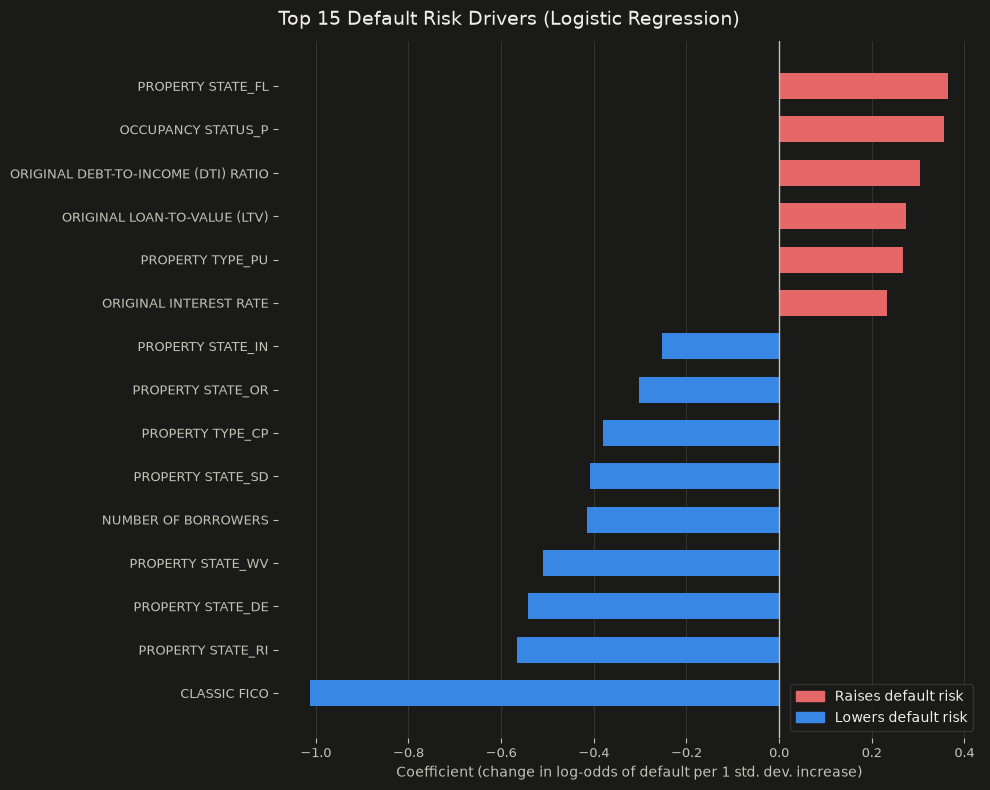

In [85]:
# ---------- Pull the coefficients out of the fitted pipeline ----------
# log_reg is a pipeline (scaler → model), so grab the logistic regression step by name
lr = log_reg.named_steps['logisticregression']

coefs = pd.DataFrame({
    'feature': X_train.columns,      # the 75 feature names, same order the model saw them
    'coef': lr.coef_[0]              # one coefficient per feature ([0] = the only row for a 2-class model)
})
coefs['abs_coef'] = coefs['coef'].abs()   # size of the effect, ignoring direction (for ranking)

# Top 15 by strength (biggest effect in either direction)
top15 = coefs.sort_values('abs_coef', ascending=False).head(15)

print("Top 15 features by coefficient strength")
display(top15[['feature', 'coef']].round(3))


# ---------- Chart ----------
# Sort by coef so risk-raising features are on top, risk-lowering at the bottom
plot_df = top15.sort_values('coef')
colors = ['#e66767' if c > 0 else '#3987e5' for c in plot_df['coef']]   # red = raises risk, blue = lowers

fig, ax = plt.subplots(figsize=(10, 8), facecolor='#1a1a19')
ax.set_facecolor('#1a1a19')

ax.barh(plot_df['feature'], plot_df['coef'], color=colors, height=0.6)
ax.axvline(0, color='#c3c2b7', linewidth=1)                 # zero line: left = lowers risk, right = raises

ax.set_title('Top 15 Default Risk Drivers (Logistic Regression)',
             color='#f0efec', fontsize=14, loc='left', pad=12)
ax.set_xlabel('Coefficient (change in log-odds of default per 1 std. dev. increase)',
              color='#c3c2b7', fontsize=10)
ax.tick_params(colors='#c3c2b7', labelsize=9)
for spine in ax.spines.values():
    spine.set_visible(False)                                 # no box around the chart
ax.grid(axis='x', color='#383835', linewidth=0.6)            # light vertical gridlines
ax.set_axisbelow(True)                                       # gridlines behind the bars

ax.legend(handles=[Patch(color='#e66767', label='Raises default risk'),
                   Patch(color='#3987e5', label='Lowers default risk')],
          loc='lower right', facecolor='#1a1a19', edgecolor='#383835', labelcolor='#f0efec')

plt.tight_layout()
plt.show()

**What the chart shows:**
- **FICO is the strongest driver by far** (-1.01). Higher credit score = lower default risk, which matches the EDA where default rate dropped in every FICO bucket.
- **LTV now comes out positive** (+0.28), so a higher loan-to-value raises risk. This matches the EDA, and confirms that dropping CLTV in Step 5d fixed the flipped sign from the first run.
- **DTI** (+0.30) and **interest rate** (+0.23) also raise risk. More of the borrower's income going to debt, and a higher rate (which usually means the lender already saw more risk), both point toward default.
- **Number of borrowers** (-0.42): loans with two borrowers are less risky than loans with one, likely because there's a second income to fall back on.
- **Occupancy status P** (+0.36): primary homes show *higher* risk than the baseline, investment properties. That seems backwards, but investment loans usually require higher credit scores and more equity to get approved, so the borrowers who get them tend to be stronger.
- **Property type:** co-ops (`CP`, -0.38) and planned unit developments (`PU`, +0.27) are compared to the baseline, condos. Co-ops are only 77 loans, so that one isn't very reliable.

- **A note on the state coefficients:** small states (RI, DE, WV, SD) can get big coefficients just because they only have ~80-160 loans each, so a couple of defaults either way swings the number a lot. Every state is also compared to the baseline state, Alaska (dropped by `drop_first=True`), which only has 93 loans. I'd be careful reading too much into those. Florida (+0.37) is the one state that stands out on the risky side.

---
## Step 13: Takeaways and Next Steps
**Takeaways**
- Built a 36-month, 90+ days past due default flag from ~3.4M rows of monthly performance data (~1.1% default rate)
- The classic underwriting variables (FICO, LTV, DTI) all lined up with default risk in the EDA
- Logistic regression and gradient boosting performed about the same in cross-validation (ROC-AUC 0.811 vs 0.816), so the simpler, explainable model was chosen
- **Final model on the test set:** ROC-AUC of **0.806** and PR-AUC of **0.070**, both close to the CV estimates (0.811 and 0.070), so the model held up on loans it had never seen
- PR-AUC is about 7× better than the random baseline (0.070 vs the 0.010 test default rate), but with a ~1% default rate, most loans the model flags will still be false alarms. That's expected for a rare event, and it's why choosing a cutoff is a business decision

**Next steps**
- **Choose a cutoff:** pick a probability threshold based on the cost of a missed default vs. the cost of a false alarm
- **Out-of-time test:** train on 2016 loans and test on a later year (e.g. 2017) to see if the model holds up over time
- **Tune Model 2:** try different tree depths, learning rates, and number of trees
- **Calibration:** check whether a predicted 5% default probability really means about 5% of those loans default